# Potencial de Artículo 6 del sector energía del Ecuador

PNUD Ecuador, Proyecto 00110180 (Climate Promise) · Dr. Ing. Mario Alejandro Heredia Salgado · Modelo Climate Lead Group de la Segunda NDC (OSeMOSYS) con las referencias con calibración propia del Artículo 6

¿Cuántas reducciones del sector energía podría transferir el Ecuador como ITMO en 2031-2035 sin poner en riesgo su meta incondicional, y qué pasa con ese potencial si sale Coca Codo o hay sequía?

Todo sale de la última corrida del modelo. El cuaderno se lee de arriba abajo: primero el modelo de la Segunda NDC y sus metas, después el sector energía en el inventario y sus iniciativas, luego los escenarios con sus pruebas de estrés y riesgos de operación, los resultados principales y la lectura para la decisión; el anexo guarda las gráficas de detalle. El código de cada celda está plegado y se despliega con el botón de la celda. Pase el cursor para ver valores, use los botones para cambiar de escenario, riesgo o regla y el ícono de cámara para descargar la imagen. Ejercicio exploratorio con fines analíticos, sin carácter de metodología oficial del Artículo 6.

Contenido: 1. El modelo de la Segunda NDC · 2. El sector energía en la NDC y en el inventario · 3. Los escenarios del análisis · 4. Resultados principales · 5. Lectura para la decisión · Anexo de gráficas · Fuentes y límites

En GitHub cada gráfica del cuaderno se ve como imagen fija. La versión interactiva de las mismas gráficas, con su guía de lectura y las piezas de los Productos 1 a 4, está en el [tablero de resultados](https://ecmaedmcc.github.io/EnergyArt6/_static/tablero_art6.html).

In [1]:
import sys
sys.path.insert(0, 'Art6_motor')
import plotly.io as pio
pio.renderers.default = 'plotly_mimetype'
from IPython.display import Markdown, display
import graficar
import explicacion
F, L = graficar.generar(png=False)   # recalcula el análisis si cambió alguna salida de B1
ver = lambda gid: graficar.mostrar(F, L, gid)
display(Markdown(graficar.estado_corrida()))

Corrida mostrada: salidas de B1 en Executables (última: 2026-11-14T14:00) con 49 escenarios con solución óptima; el análisis está al día con ellas.

## 1. El modelo de la Segunda NDC

El tendencial, los dos tramos de la meta, cuándo se reporta el cumplimiento y la gráfica de referencias con el inventario observado.

In [2]:
explicacion.mostrar_lectura('ndc')

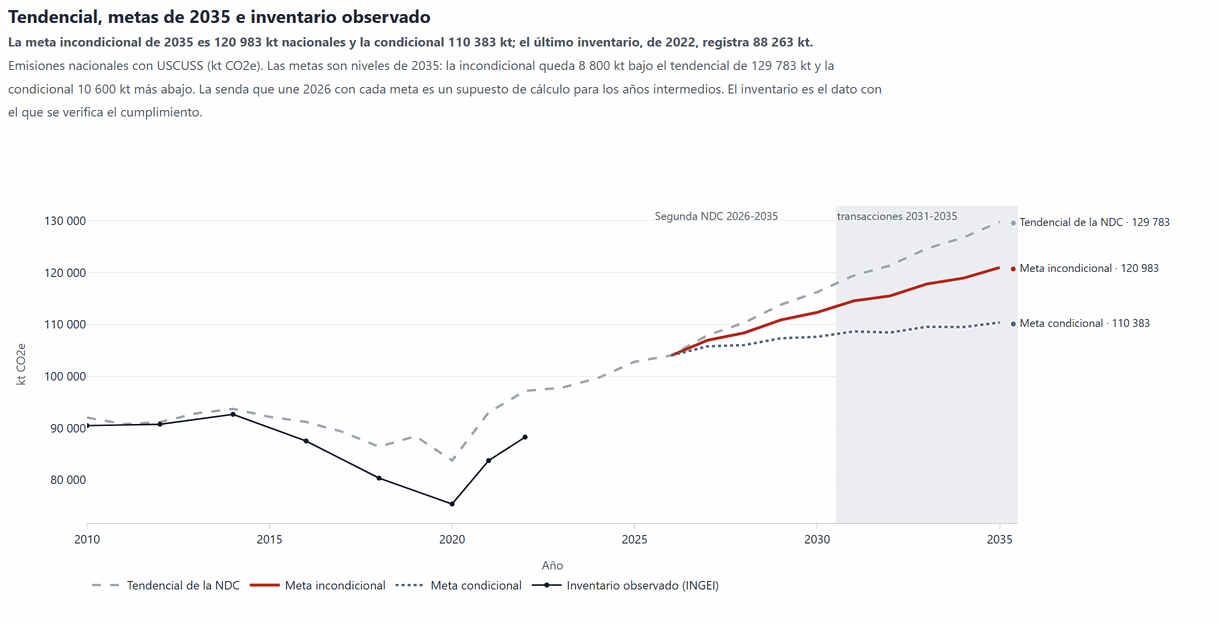

In [3]:
ver('g18_referencias')

## 2. El sector energía en la NDC y en el inventario

Peso del sector y gases según el inventario, cobertura y calibración del modelo, y las iniciativas de la Segunda NDC en el sector.

In [4]:
explicacion.mostrar_lectura('sector')

Iniciativa,Tramo,Periodo,kt/año declarado,En este ejercicio,Adicionalidad
EN01 Operación Comercial del Tranvía de Cuenca,Incondicional,2026-2035,"15,0",fuera del portafolio,No transferible
EN03 Modernización del Sistema de Transporte Público Metropolitano de Pasajeros de Quito a través de la Dotación de Trolebuses,Incondicional,2026-2035,"5,0",fuera del portafolio,No transferible
EN04 Proyecto Primera Línea del Metro de Quito,Incondicional,2026-2035,"60,0",fuera del portafolio,No transferible
EN06 Programa de Soluciones Energéticas Upstream,Incondicional,2026-2035,"428,6",fuera del portafolio,No transferible
EN07 Preparación y Despacho de Gasolinas con Etanol,Incondicional,2026-2035,"199,1",fuera del portafolio,No transferible
EN13 Central Hidroeléctrica Coca Codo Sinclair,Incondicional,2026-2035,"3 927,0",fuera del portafolio,No transferible
EN14 Central Hidroeléctrica Manduriacu,Incondicional,2026-2035,"168,0",fuera del portafolio,No transferible
EN15 Central Hidroeléctrica Mazar,Incondicional,2026-2035,"255,0",fuera del portafolio,No transferible
EN16 Central Hidroeléctrica Minas San Francisco,Incondicional,2026-2035,"529,0",fuera del portafolio,No transferible
EN17 Central Hidroeléctrica Sopladora,Incondicional,2026-2035,"1 150,0",fuera del portafolio,No transferible


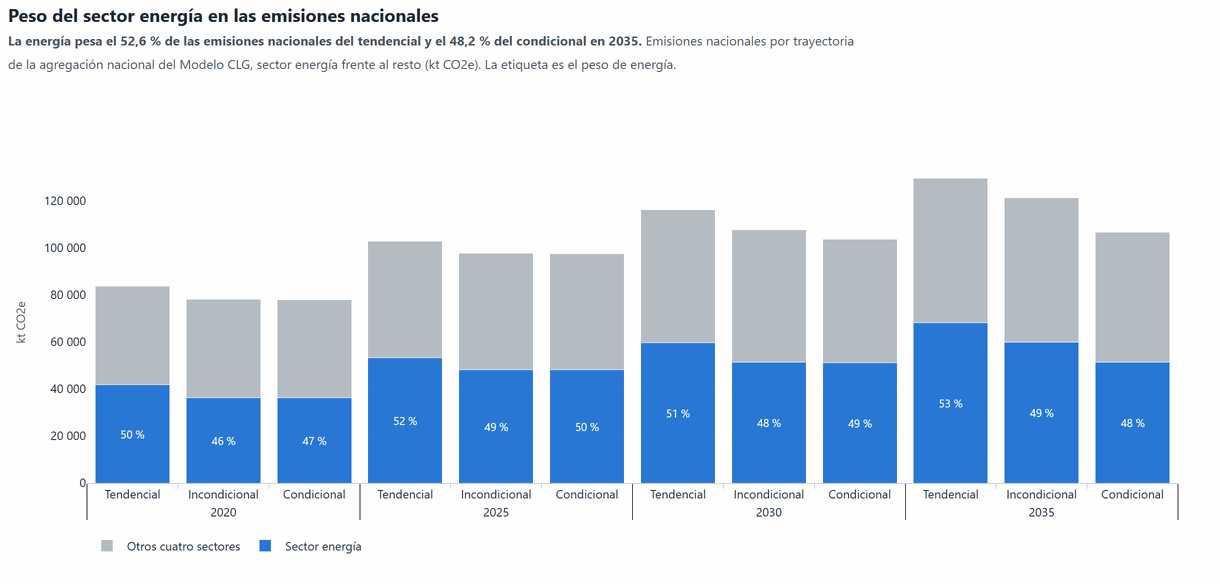

In [5]:
ver('g11_peso_energia')

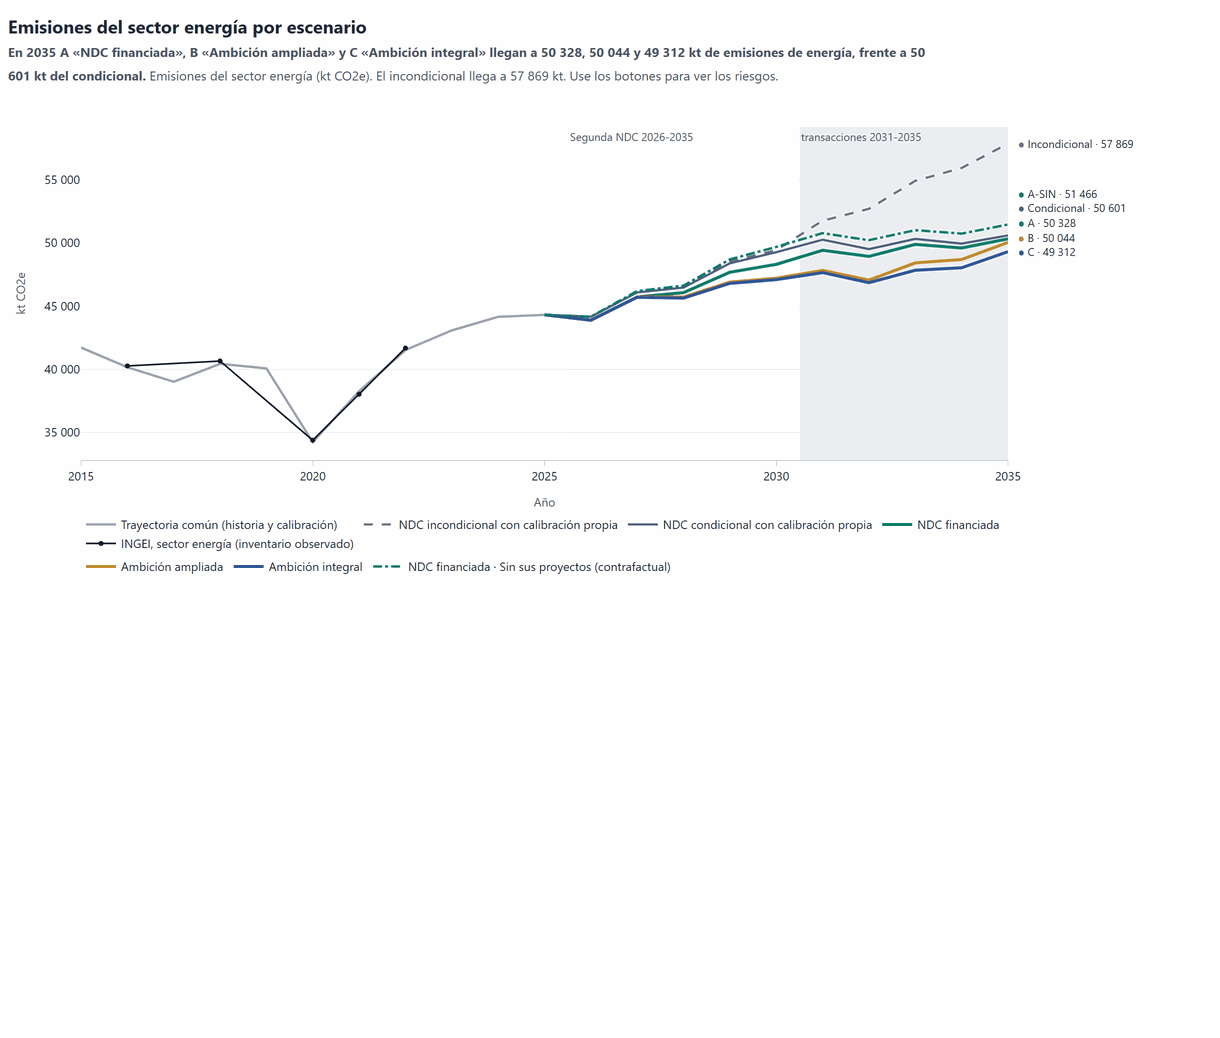

In [6]:
ver('g03_energia_escenarios')

## 3. Los escenarios del análisis

Los términos del ejercicio, qué es cada escenario y qué pregunta responde; el mapa, la ficha de cada uno con sus iniciativas modeladas y los parámetros de entrada.

In [7]:
explicacion.mostrar_lectura('glosario')

Término,Definición
Palanca,"Una fila de la hoja Electrical del libro de configuración: fija un parámetro de OSeMOSYS para una tecnología y un periodo (un techo o un piso de capacidad o de generación, una inversión mínima, un factor de planta). Cada escenario es la copia del condicional más sus palancas; la hoja Art6_Palancas las documenta una por una."
Techo y piso,"Límites que el optimizador no puede cruzar: el techo (TotalAnnualMaxCapacity, TotalTechnologyAnnualActivityUpperLimit) acota por arriba la capacidad o la generación de una tecnología; el piso (…LowerLimit) obliga a un mínimo. En los escenarios A y B los techos son el potencial de la capacidad declarada y el despacho lo decide el modelo, salvo el piso geotérmico de Chachimbiro (A5) y los pisos térmicos, que fijan una generación mínima: el de fuel oil es K16, el mínimo observado 2015-2025, y los de diésel y gas natural son los del Modelo CLG."
Inversión mínima,"TotalAnnualMinCapacityInvestment: capacidad que el modelo debe construir en un año dado. Así entran los proyectos declarados (eólica, solar, geotermia, biomasa) con su año de operación."
Factor de planta,"CapacityFactor: fracción del año en que una central opera a plena potencia. La eólica del A usa el valor observado (0,359) y el año seco aplica a cada clase hidroeléctrica la razón entre el caudal de 2024 y su media histórica."
Capa,"Diferencia de emisiones del sector energía entre un escenario y su base, sumada en el marco 2026-2035 de la Segunda NDC y, para la oferta, en la ventana de transacciones 2031-2035. La capa del A se mide frente al condicional; la del B, frente al A; la del C, frente al B."
Contrafactual y aporte atribuible,El contrafactual es el mismo sistema sin los proyectos del escenario (A sin sus proyectos). La diferencia de emisiones con el escenario es el aporte atribuible por retiro: lo que esos proyectos reducen antes de las pruebas de adicionalidad y de sobreventa.
Margen,"Distancia, en 2035, entre la meta incondicional y las emisiones nacionales del escenario: lo que puede transferirse con ajuste correspondiente sin incumplir la meta. Negativo: incumple."
Regla base y regla prudente,"Cómo se proyectan los sectores que el modelo no cubre. Regla base: cumplen su tramo condicional. Regla prudente: cumplen solo su tramo incondicional, lo que deja menos margen. Toda cifra de margen se reporta con las dos."
Riesgo,"Prueba de estrés sobre el sistema. Coca Codo: el derrateo del 20 % de Coca Codo Sinclair desde 2027 (CCDER), la salida de Coca Codo sola desde 2029 (CCSOLO, caso central) y la salida de la clase de Coca Codo, Coca Codo Sinclair y Sopladora, desde 2029 (CCOFF). Hidrología: el año seco severo con los caudales de 2024 todos los años desde 2026 (ANOSECO, cota), un año seco cada tres (ANOSEC3, caso central) y el año seco moderado (ANOSECM). Además, la salida de la clase y el año seco severo a la vez (CCOFFANOSECO) y la importación cero desde Colombia (IMP0), y la situación actual anclada a 2026 (ACT y ACT-DEM): en 2026, la demanda, la hidrología por clase, Coca Codo y la importación observadas; desde 2027, un año seco cada tres e importación cero; en ACT la demanda vuelve a la del Modelo CLG desde 2027 y en ACT-DEM el nivel de 2026 persiste. Los estados de riesgo llevan un respaldo de emergencia (tope de fuel oil liberado con potencia nueva cara y STOELE cerrado), supuesto de cierre como la térmica arrendada que el país contrata hoy. Riesgo de operación: sin pisos térmicos (FOI), un cambio de operación que no es un proyecto y no genera unidades; por eso queda fuera de los volúmenes transferibles."
Adicionalidad,Condición de que la reducción no ocurriría sin el ingreso del mercado. Firme: proyecto con barreras demostradas; por demostrar: pendiente de memoria de cálculo; sin adicionalidad: proyectos que se ejecutan de todos modos. El veredicto de compradores (hoja Art6_Adicionalidad) la completa.


In [8]:
explicacion.mostrar_lectura('escenarios')

Escenario,Qué representa,"Emisiones de energía en 2035, kt",Para qué sirve
NDC incondicional con calibración propia INCA6,referencia con calibración propia del Artículo 6: NDCINC del Modelo CLG con los ajustes de calibración K01-K15; el país cumple solo su tramo incondicional,57 869,base reservada; contra ella se mide la sobreventa
NDC condicional con calibración propia CONA6,"referencia con calibración propia del Artículo 6: NDCCON del Modelo CLG con los ajustes de calibración K01-K15, con sus techos y pisos",50 601,la proyección de la NDC con apoyo internacional: 7 268 kt bajo el incondicional en 2035
NDC financiada A,"El Ecuador financia con mercado de carbono una parte de su NDC condicional y esas actividades rinden lo que declaran: techos de generación iguales al potencial de la capacidad existente y declarada, con el factor de planta observado de la base con calibración propia, y Chachimbiro adelantado a la fecha del Plan de Expansión.",50 328,"capa de 2 473,1 kt en 2031-2035 frente al condicional; aporte atribuible por retiro de 6 048,4 kt (A-SIN menos A)"
NDC financiada · Sin sus proyectos (contrafactual) A-SIN,el sistema de A sin las actividades que A financia,51 466,escenario de referencia de esas actividades; su diferencia con A es el aporte atribuible
Ambición ampliada B,"Sobre el A, un paquete fuera de la Segunda NDC entra como capacidad construida: la eólica del Plan de Expansión, el portafolio solar de CELEC EP con la AFD y 39,3 MW de biomasa del portafolio ESIN-CELEC EP.",50 044,"capa de 6 129,0 kt en 2031-2035 frente a A"
Ambición integral C,"Sobre el B, la demanda del Plan de Acción del PLANMICC (electromovilidad y eficiencia industrial) y la geotermia de Tufiño-Chiles-Cerro Negro en 2035.",49 312,"capa de 2 350,2 kt en 2031-2035 frente a B"
"Salida de la clase de Coca Codo (Coca Codo Sinclair y Sopladora) A-CCOFF, B-CCOFF, C-CCOFF",riesgo sobre el sistema,52 524 a 56 685,margen de 2035 entre 1 184 y 5 345 kt con la regla prudente
"Salida de Coca Codo sola (caso central) A-CCSOLO, B-CCSOLO, C-CCSOLO",riesgo sobre el sistema,50 910 a 54 707,margen de 2035 entre 3 162 y 6 958 kt con la regla prudente
"Derrateo de Coca Codo A-CCDER, B-CCDER, C-CCDER",riesgo sobre el sistema,49 312 a 51 086,margen de 2035 entre 6 782 y 8 557 kt con la regla prudente
"Año seco severo (cota) A-ANOSECO, B-ANOSECO, C-ANOSECO",riesgo sobre el sistema,51 842 a 55 971,margen de 2035 entre 1 898 y 6 027 kt con la regla prudente


In [9]:
explicacion.mostrar_mapa()

,Sistema intactosin choques,Salida de la clase de Coca Codo (Coca Codo Sinclair y Sopladora)riesgo · desde 2029,Salida de Coca Codo sola (caso central)riesgo · desde 2029,Derrateo de Coca Codoriesgo · desde 2027,Año seco severo (cota)riesgo · desde 2026,Un año seco cada tres (caso central)riesgo · desde 2026,Año seco moderadoriesgo · desde 2026,Salida de la clase de Coca Codo y año seco severoriesgo · desde 2026,Sin pisos térmicos (K16 en PPFOI; Modelo CLG en PPDSL y PPNGS)riesgo de operación · desde 2026,Importación cero desde Colombiariesgo · desde 2026,"Situación actual 2026, demanda transitoria (ACT)riesgo · desde 2026","Situación actual 2026, demanda persistente (ACT-DEM)riesgo · desde 2026",Sin la expansión a gas declarada (sobre CONA6G)riesgo de operación,Sin sus proyectos (contrafactual)contrafactual · desde 2026
NDC financiada,AVolumen adicional2 473 ktMargen 203510 872 ktprudente: 7 540 kt,A-CCOFFVolumen adicional0 ktMargen 20354 515 ktprudente: 1 184 kt,A-CCSOLOVolumen adicional0 ktMargen 20356 494 ktprudente: 3 162 kt,A-CCDERVolumen adicional0 ktMargen 203510 114 ktprudente: 6 782 kt,A-ANOSECOVolumen adicional0 ktMargen 20355 230 ktprudente: 1 898 kt,A-ANOSEC3Volumen adicional1 678 ktMargen 20355 230 ktprudente: 1 898 kt,A-ANOSECMVolumen adicional0 ktMargen 20359 182 ktprudente: 5 850 kt,A-CCOFFANOSECOVolumen adicional0 ktMargen 2035−1 040 ktprudente: −4 372 kt,A-FOIVolumen adicional3 648 ktMargen 203511 200 ktprudente: 7 868 kt,A-IMP0Volumen adicional1 035 ktMargen 203510 601 ktprudente: 7 269 kt,A-ACTVolumen adicional776 ktMargen 20354 852 ktprudente: 1 520 kt,A-ACTDEMVolumen adicional0 ktMargen 2035960 ktprudente: −2 372 kt,A-GASVolumen adicional260 ktMargen 203510 805 ktprudente: 7 473 kt,A-SINVolumen adicional0 ktMargen 20359 735 ktprudente: 6 403 kt
Ambición ampliada,BVolumen adicional8 602 ktMargen 203511 156 ktprudente: 7 825 kt,B-CCOFFVolumen adicional0 ktMargen 20357 779 ktprudente: 4 447 kt,B-CCSOLOVolumen adicional0 ktMargen 20359 439 ktprudente: 6 107 kt,B-CCDERVolumen adicional6 897 ktMargen 203511 156 ktprudente: 7 825 kt,B-ANOSECOVolumen adicional0 ktMargen 20358 469 ktprudente: 5 137 kt,B-ANOSEC3Volumen adicional5 605 ktMargen 20358 469 ktprudente: 5 137 kt,B-ANOSECMVolumen adicional4 625 ktMargen 203511 156 ktprudente: 7 825 kt,B-CCOFFANOSECOVolumen adicional0 ktMargen 20352 223 ktprudente: −1 108 kt,B-FOIVolumen adicional13 104 ktMargen 203512 632 ktprudente: 9 300 kt,B-IMP0Volumen adicional8 060 ktMargen 203511 156 ktprudente: 7 825 kt,B-ACTVolumen adicional5 334 ktMargen 20358 109 ktprudente: 4 777 kt,B-ACTDEMVolumen adicional0 ktMargen 20354 076 ktprudente: 744 kt,B-GASVolumen adicional8 194 ktMargen 203511 156 ktprudente: 7 825 kt,sin corrida
Ambición integral,CVolumen adicional10 952 ktMargen 203511 888 ktprudente: 8 557 kt,C-CCOFFVolumen adicional0 ktMargen 20358 677 ktprudente: 5 345 kt,C-CCSOLOVolumen adicional0 ktMargen 203510 290 ktprudente: 6 958 kt,C-CCDERVolumen adicional8 909 ktMargen 203511 888 ktprudente: 8 557 kt,C-ANOSECOVolumen adicional0 ktMargen 20359 359 ktprudente: 6 027 kt,C-ANOSEC3Volumen adicional7 016 ktMargen 20359 359 ktprudente: 6 027 kt,C-ANOSECMVolumen adicional6 183 ktMargen 203511 888 ktprudente: 8 557 kt,C-CCOFFANOSECOVolumen adicional0 ktMargen 20353 121 ktprudente: −211 kt,sin corrida,C-IMP0Volumen adicional10 328 ktMargen 203511 888 ktprudente: 8 557 kt,C-ACTVolumen adicional6 663 ktMargen 20358 999 ktprudente: 5 667 kt,C-ACTDEMVolumen adicional0 ktMargen 20354 908 ktprudente: 1 576 kt,C-GASVolumen adicional10 344 ktMargen 203511 888 ktprudente: 8 557 kt,sin corrida


In [10]:
explicacion.mostrar_fichas()

Código,Iniciativa,Periodo,kt/año declarados,Adicionalidad
EN13,Central Hidroeléctrica Coca Codo Sinclair,2026-2035,"3 927,0",No transferible
EN17,Central Hidroeléctrica Sopladora,2026-2035,"1 150,0",No transferible
EN23,Complejo Hidroeléctrico Toachi Pilatón,2026-2035,"537,0",No transferible
EN16,Central Hidroeléctrica Minas San Francisco,2026-2035,"529,0",No transferible
EN06,Programa de Soluciones Energéticas Upstream,2026-2035,"428,6",No transferible
EN21,Proyecto Hidroeléctrico Delsitanisagua,2026-2035,"369,0",No transferible
EN15,Central Hidroeléctrica Mazar,2026-2035,"255,0",No transferible
EN07,Preparación y Despacho de Gasolinas con Etanol,2026-2035,"199,1",No transferible
EN14,Central Hidroeléctrica Manduriacu,2026-2035,"168,0",No transferible
EN04,Proyecto Primera Línea del Metro de Quito,2026-2035,"60,0",No transferible


In [11]:
explicacion.mostrar_supuestos()

In [12]:
explicacion.mostrar_lectura('hidro')

Clase,Tipo,Vertiente,Tamaño,MW 2026 (CONA6),MW 2035,GWh 2026,Centrales de referencia,Papel en los riesgos
PPHDAMAB,embalse,amazónica (oriental),grande,1 075,3 011,5 151,sin centrales de referencia en la hoja,año seco: caudales de 2024
PPHDAMAM,embalse,amazónica (oriental),mediana,330,330,1 582,sin centrales de referencia en la hoja,año seco: caudales de 2024
PPHDAMAS,embalse,amazónica (oriental),pequeña,3,8,6,sin centrales de referencia en la hoja,año seco: caudales de 2024
PPHDAMPM,embalse,del Pacífico (occidental),mediana,423,492,1 867,sin centrales de referencia en la hoja,año seco: caudales de 2024
PPHDAMPS,embalse,del Pacífico (occidental),pequeña,91,91,249,sin centrales de referencia en la hoja,año seco: caudales de 2024
PPHRORAB,pasada,amazónica (oriental),grande,1 987,1 987,9 386,sin centrales de referencia en la hoja,"sale de operación desde 2029 (CCOFF, salida de la clase); Coca Codo sola desde 2029 (CCSOLO); derrateo desde 2027 (CCDER); año seco: caudales de 2024"
PPHRORAM,pasada,amazónica (oriental),mediana,561,561,1 761,sin centrales de referencia en la hoja,año seco: caudales de 2024
PPHRORAS,pasada,amazónica (oriental),pequeña,62,62,419,sin centrales de referencia en la hoja,año seco: caudales de 2024
PPHRORPM,pasada,del Pacífico (occidental),mediana,601,601,1 514,sin centrales de referencia en la hoja,año seco: caudales de 2024
PPHRORPS,pasada,del Pacífico (occidental),pequeña,150,150,904,sin centrales de referencia en la hoja,año seco: caudales de 2024


## 4. Resultados principales

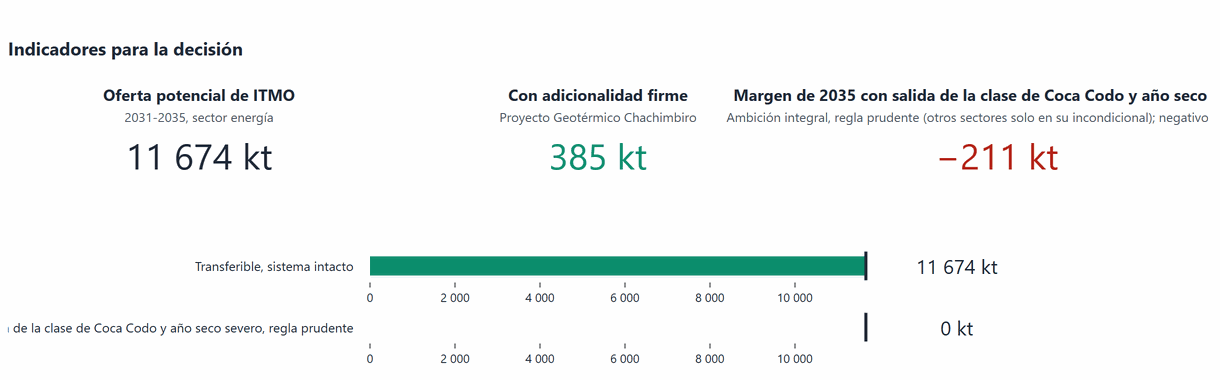

In [13]:
ver('g00_indicadores')

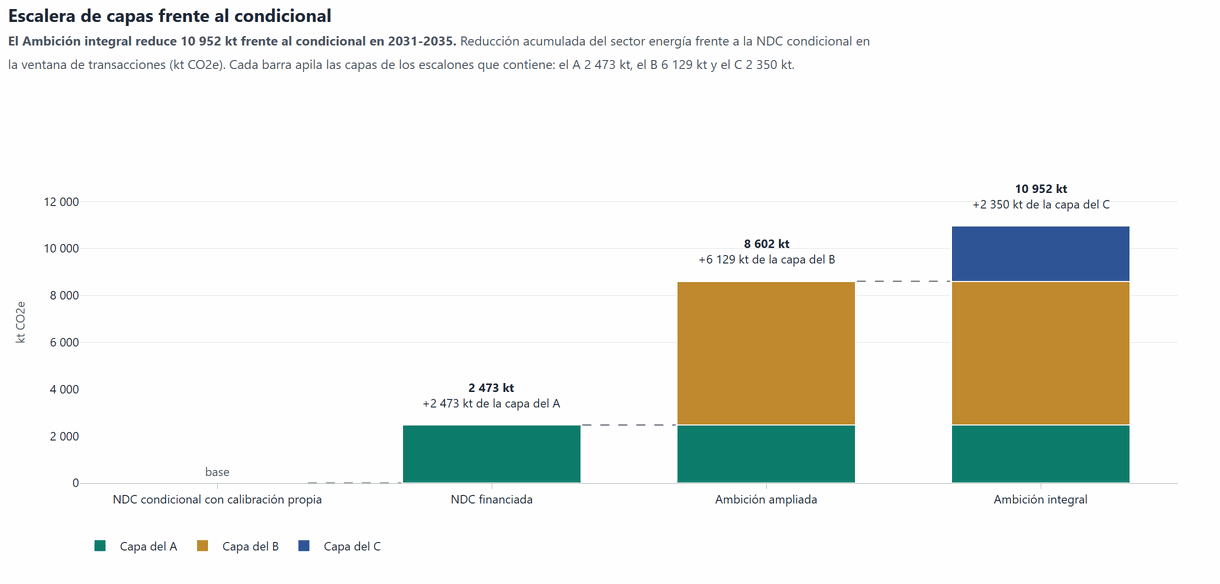

In [14]:
ver('g20_escalera')

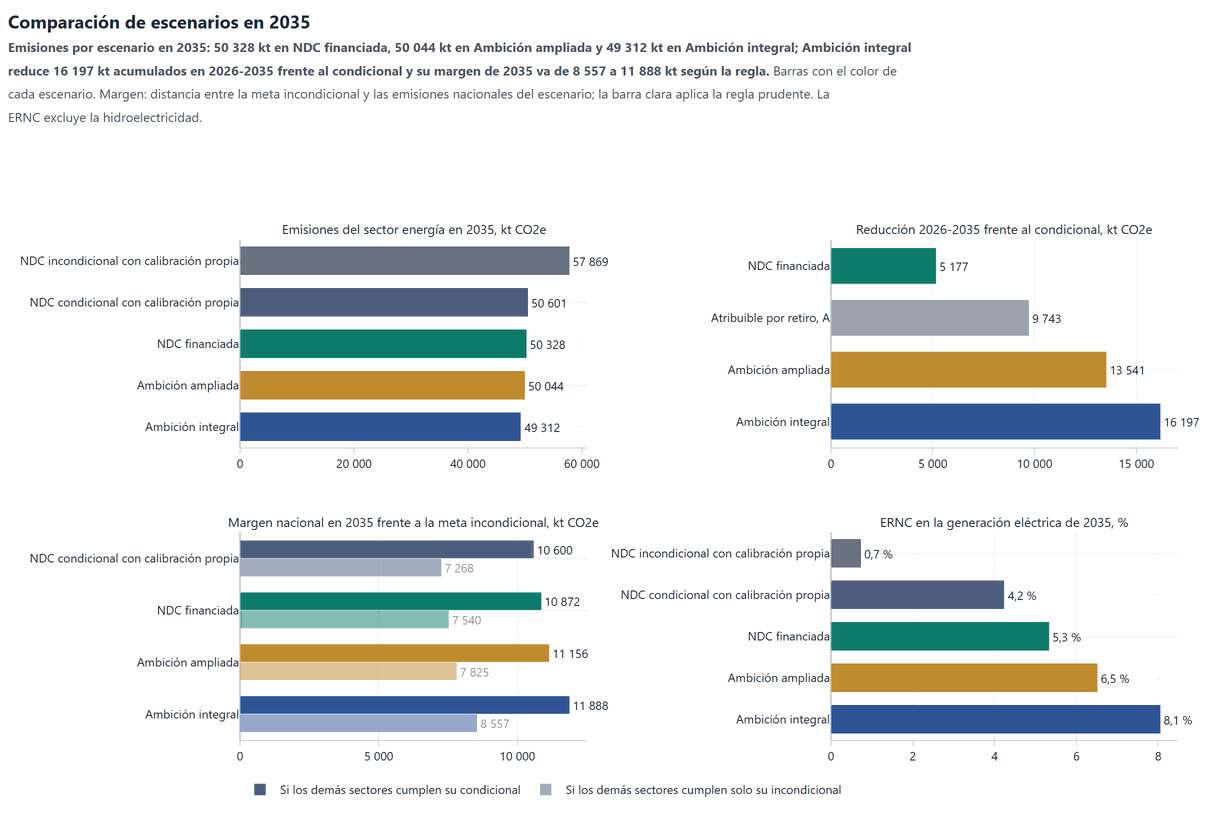

In [15]:
ver('g19_comparacion')

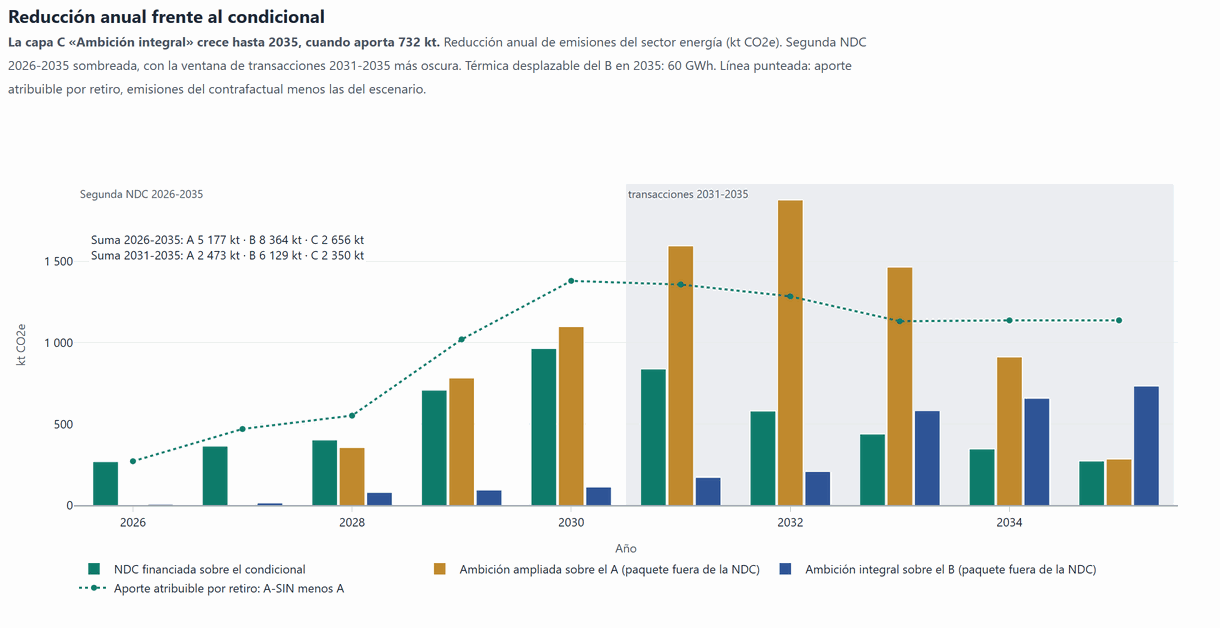

In [16]:
ver('g04_reduccion_anual')

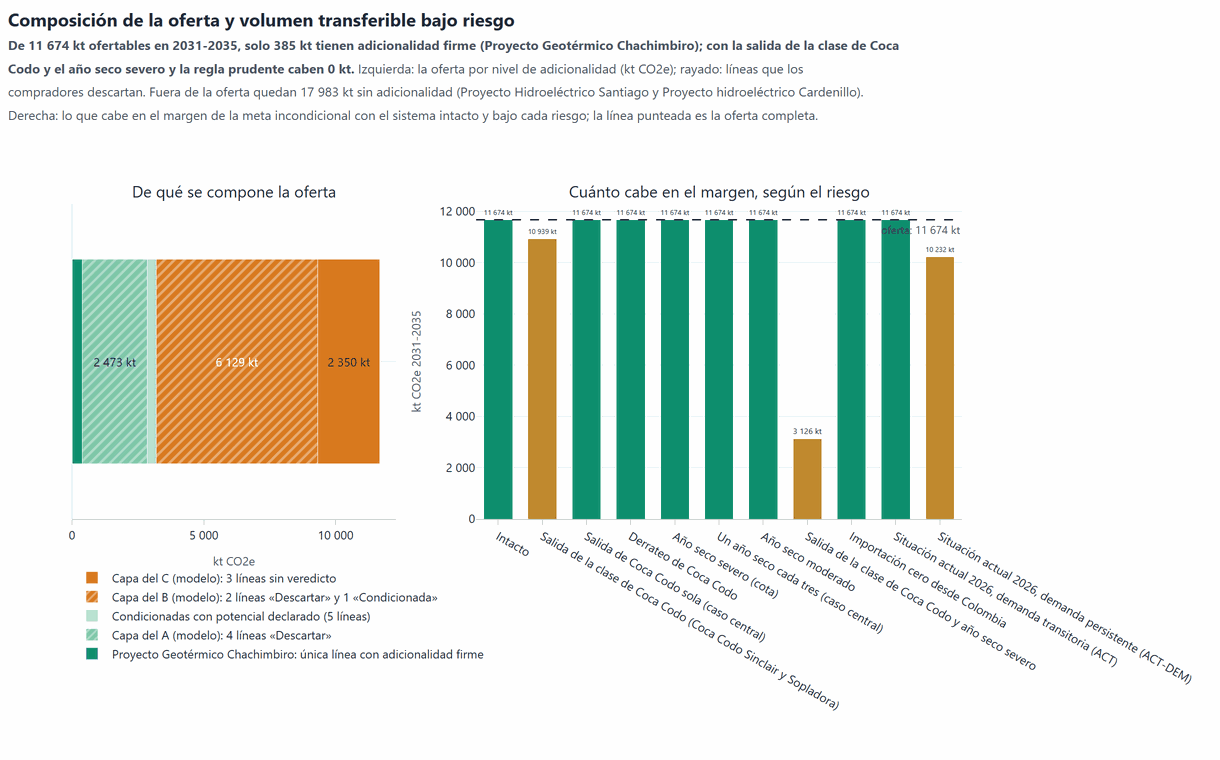

In [17]:
ver('g02_potencial')

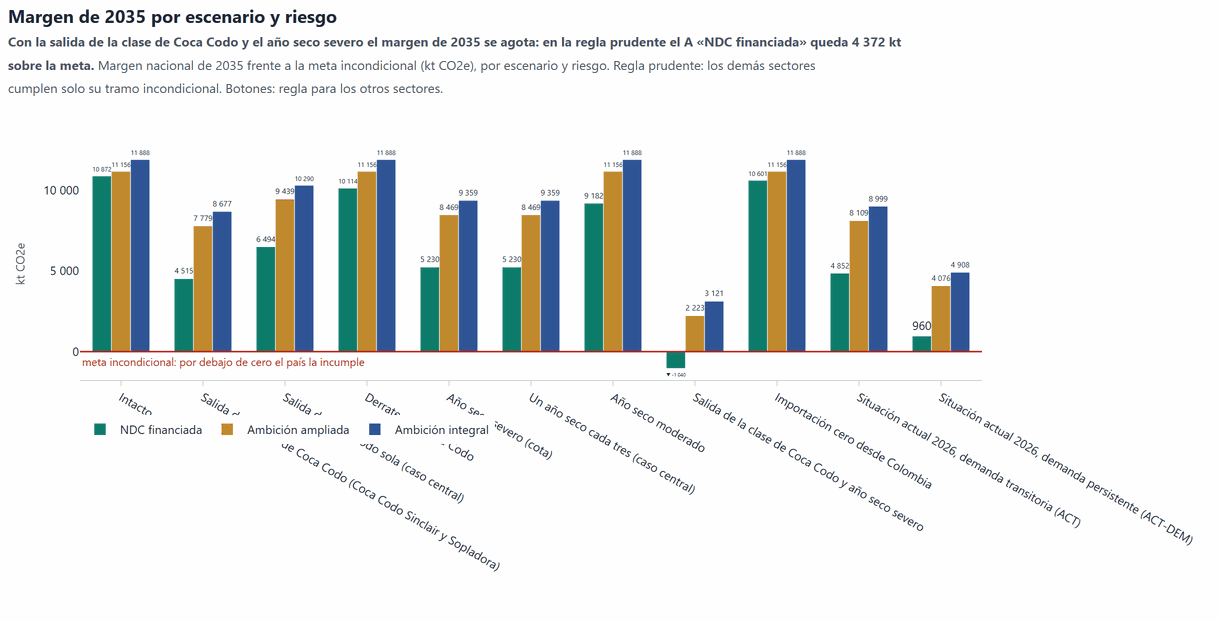

In [18]:
ver('g14_headroom_riesgos')

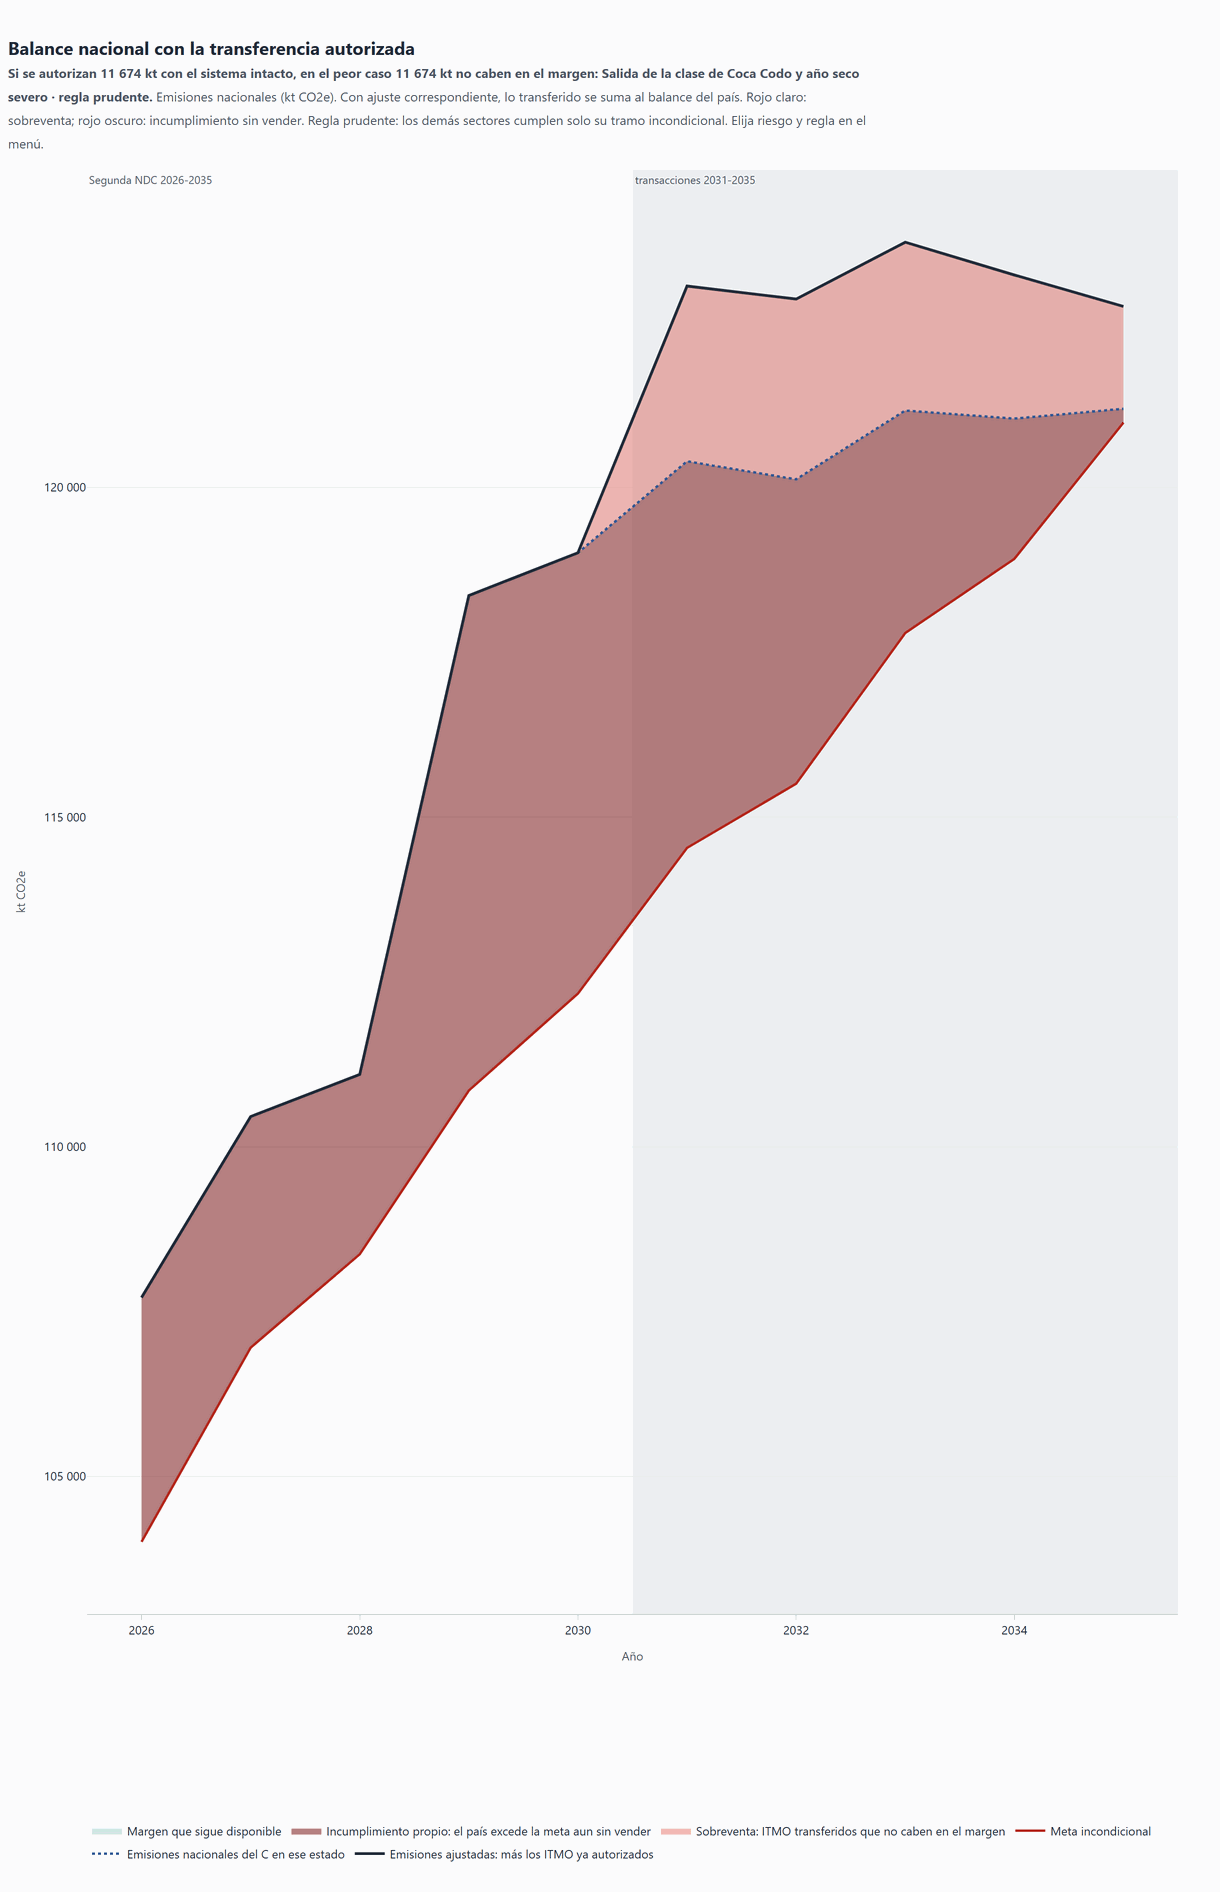

In [19]:
ver('g13_sobreventa_area')

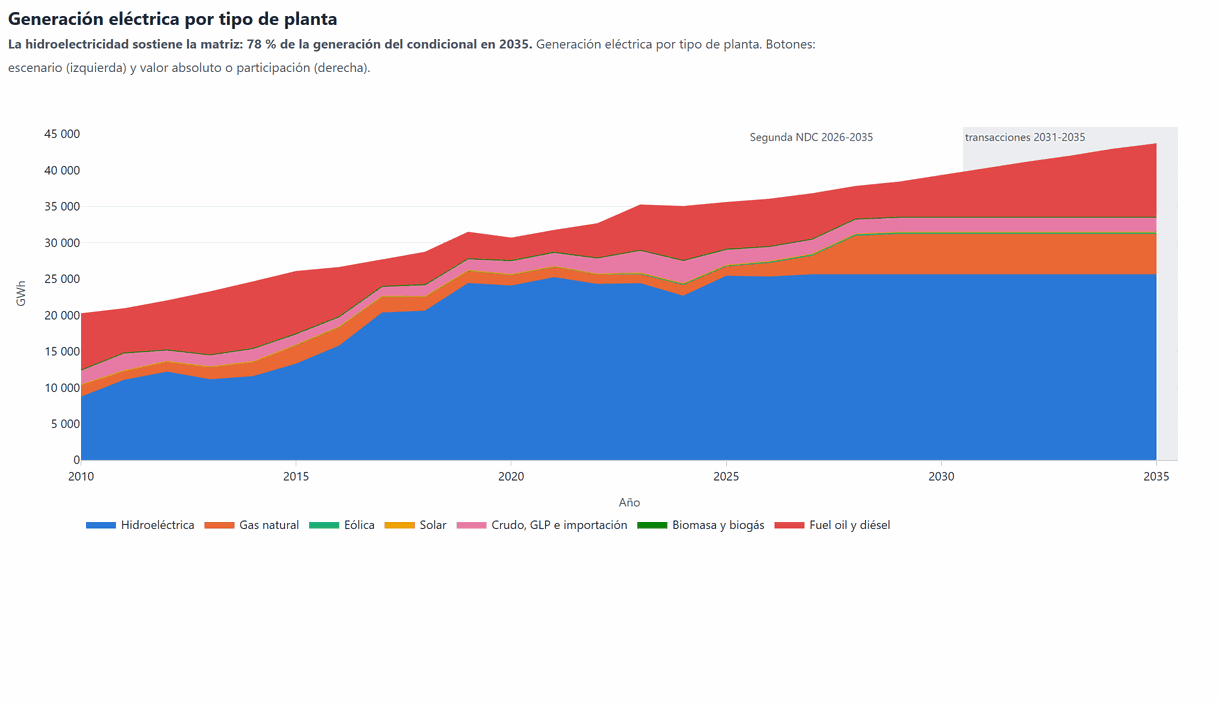

In [20]:
ver('g07_generacion')

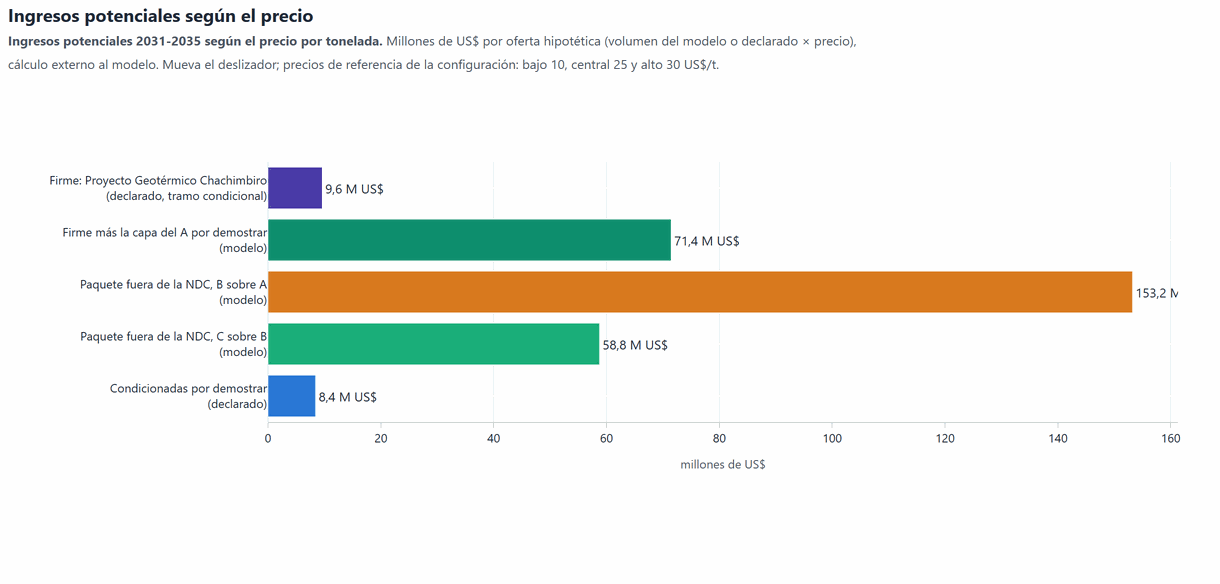

In [21]:
ver('g17_ingresos')

## 5. Lectura para la decisión

In [22]:
explicacion.mostrar_lectura('decision')

In [23]:
explicacion.mostrar_lectura('riesgo')

Estado,"CLG, regla prudente (autorización)","CLG, regla condicional","Con efecto de calibración, regla condicional","Con efecto de calibración, regla prudente"
Sistema intacto,0 ktsin año negativo,0 ktsin año negativo,0 ktsin año negativo,0 ktsin año negativo
Salida de la clase de Coca Codo (Coca Codo Sinclair y Sopladora),6 785 ktprimer año negativo 2031,736 ktprimer año negativo 2031,0 ktsin año negativo,4 055 ktprimer año negativo 2031
Salida de Coca Codo sola (caso central),4 006 ktprimer año negativo 2031,0 ktsin año negativo,0 ktsin año negativo,1 251 ktprimer año negativo 2031
Derrateo de Coca Codo,0 ktsin año negativo,0 ktsin año negativo,0 ktsin año negativo,0 ktsin año negativo
Año seco severo (cota),3 651 ktprimer año negativo 2031,0 ktsin año negativo,0 ktsin año negativo,682 ktprimer año negativo 2031
Un año seco cada tres (caso central),1 080 ktprimer año negativo 2032,0 ktsin año negativo,0 ktsin año negativo,0 ktsin año negativo
Año seco moderado,0 ktsin año negativo,0 ktsin año negativo,0 ktsin año negativo,0 ktsin año negativo
Salida de la clase de Coca Codo y año seco severo,11 674 ktprimer año negativo 2031,8 548 ktprimer año negativo 2031,4 841 ktprimer año negativo 2031,10 123 ktprimer año negativo 2031
Importación cero desde Colombia,0 ktsin año negativo,0 ktsin año negativo,0 ktsin año negativo,0 ktsin año negativo
"Situación actual 2026, demanda transitoria (ACT)",1 458 ktprimer año negativo 2032,0 ktsin año negativo,0 ktsin año negativo,0 ktsin año negativo


## Anexo de gráficas

Detalle para quien quiera profundizar: oferta de ITMO por año, emisiones de la generación, subsectores, capacidad, ERNC, trayectorias nacionales, cascada y trayectoria del margen y volúmenes por regla.

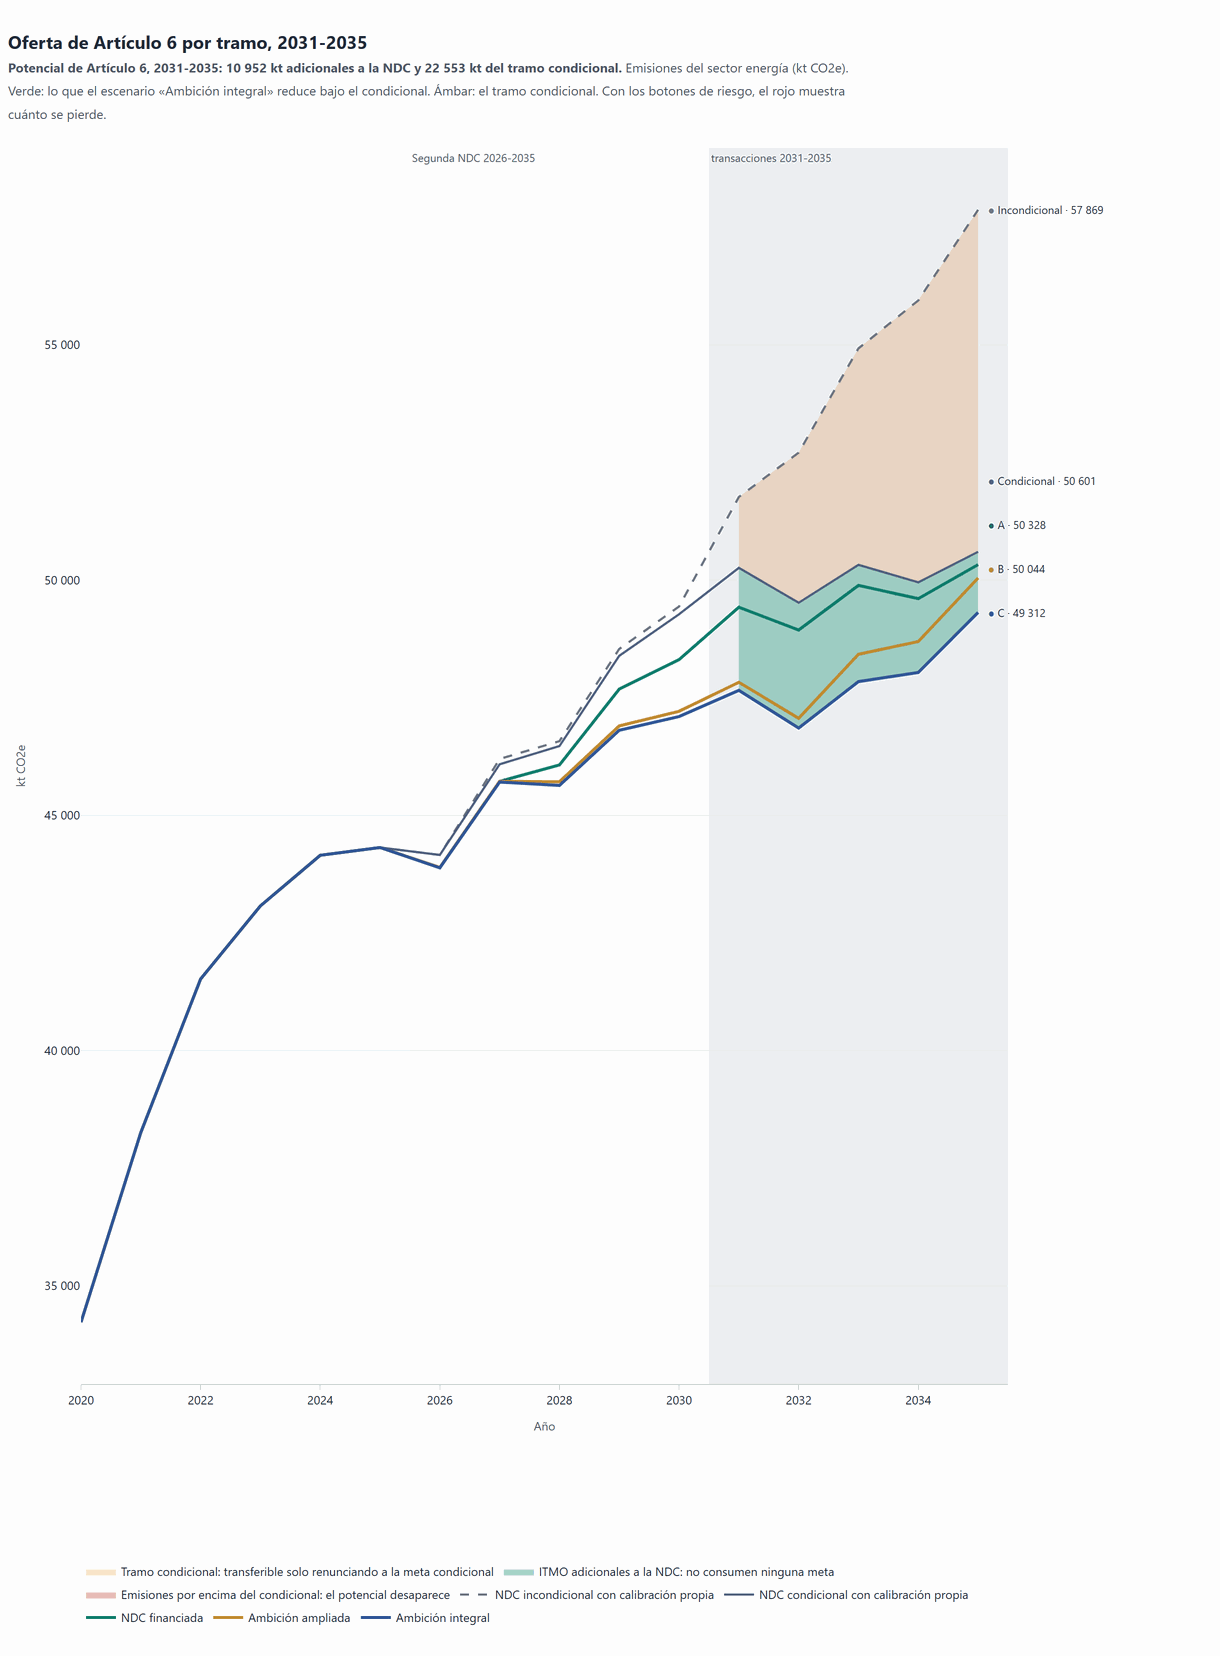

In [24]:
ver('g01_itmos_area')

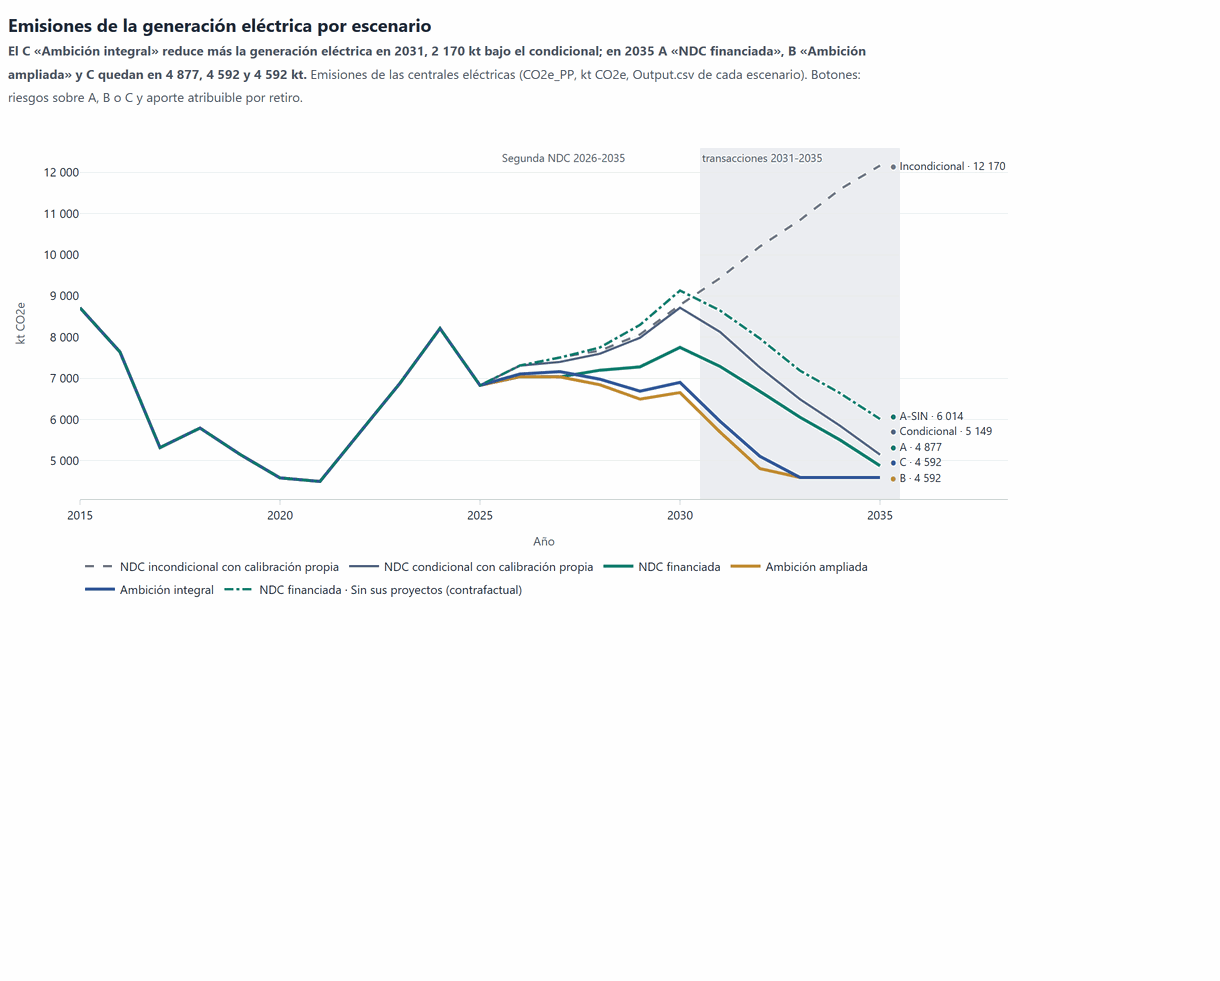

In [25]:
ver('g05_emisiones_generacion')

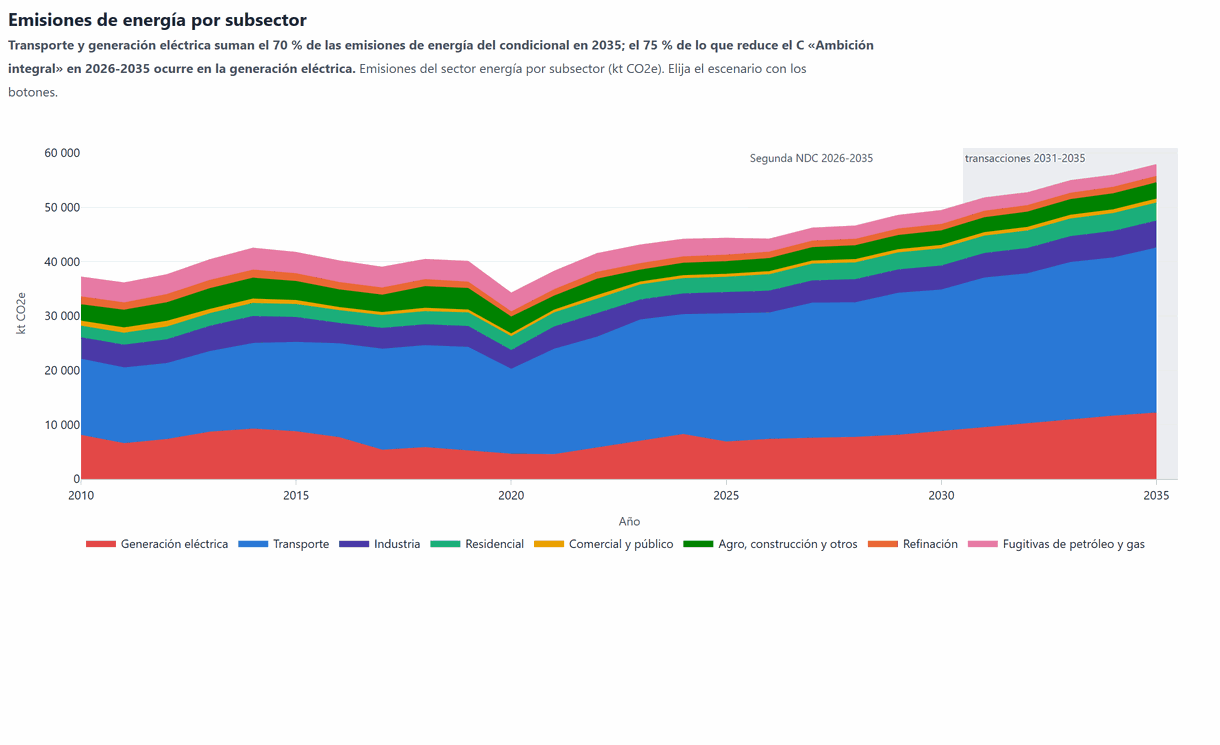

In [26]:
ver('g06_subsectores')

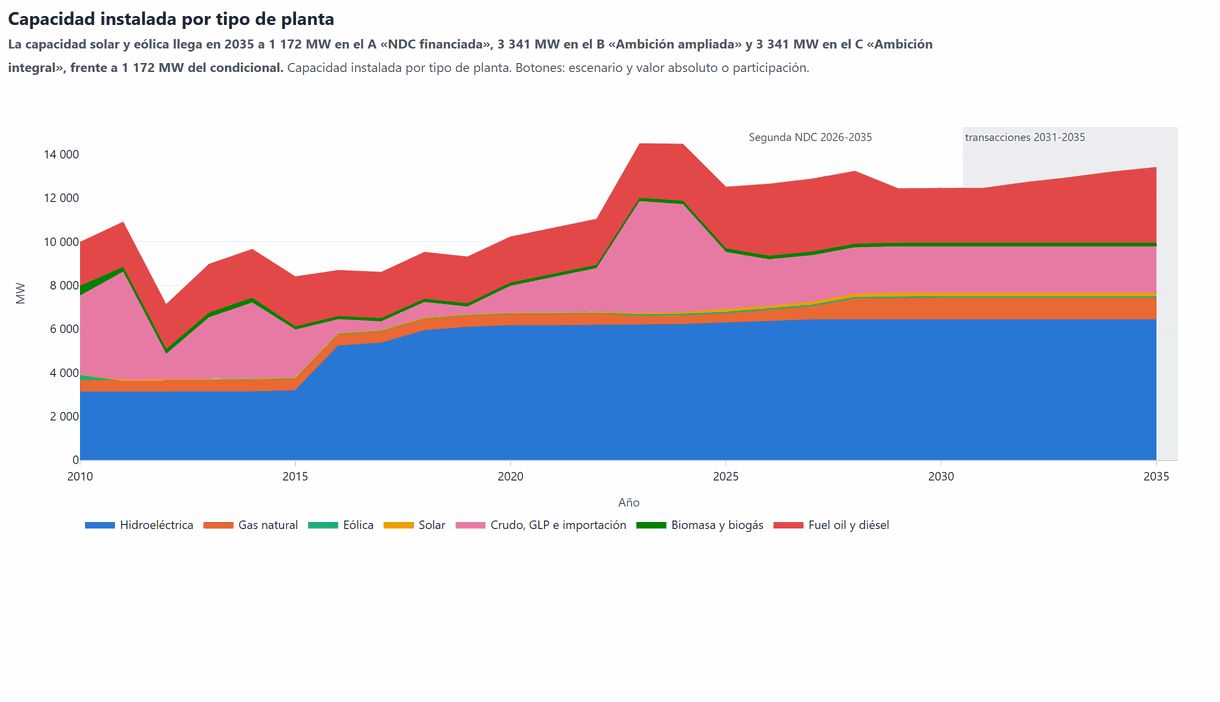

In [27]:
ver('g08_capacidad')

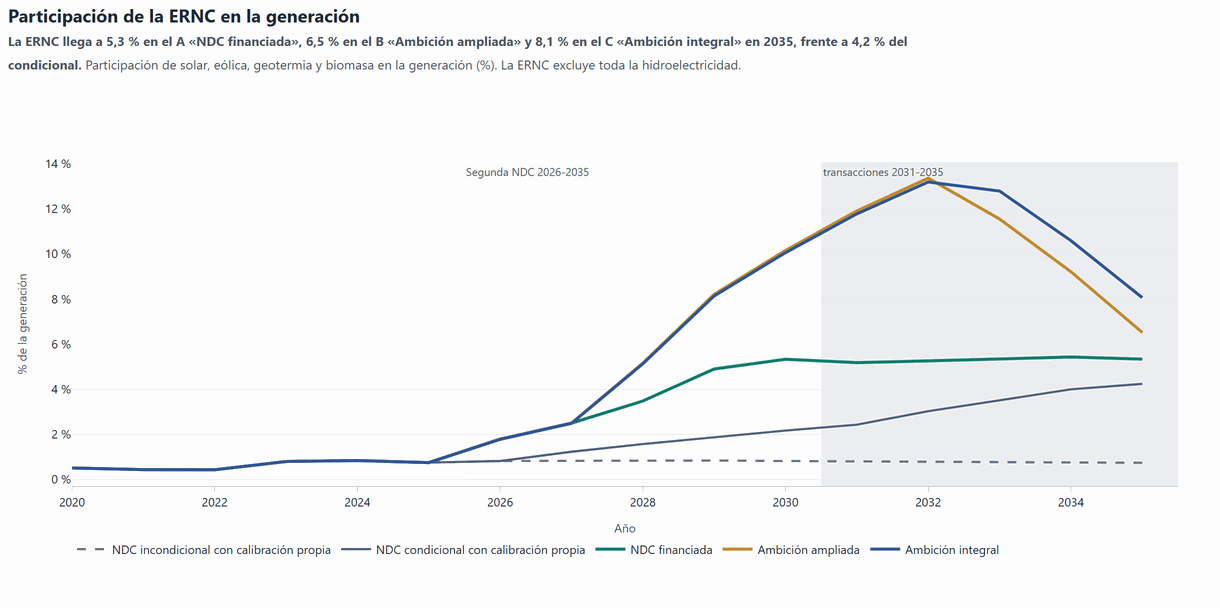

In [28]:
ver('g09_ernc')

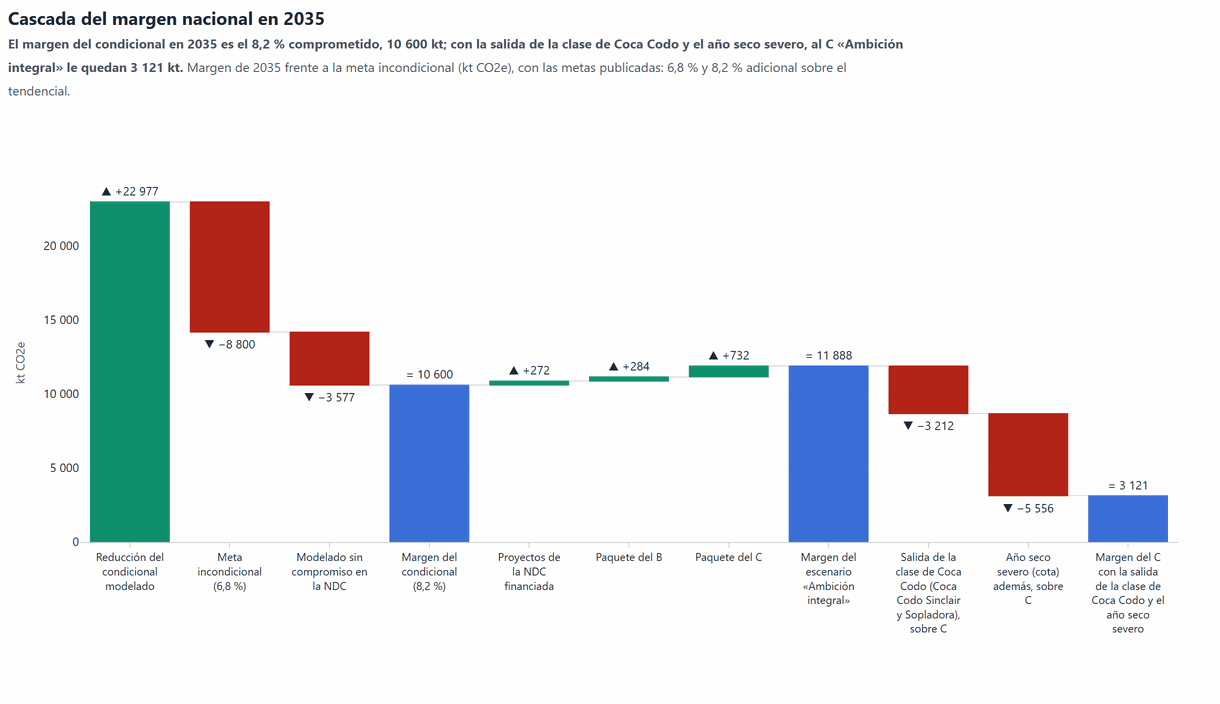

In [29]:
ver('g12_cascada_headroom')

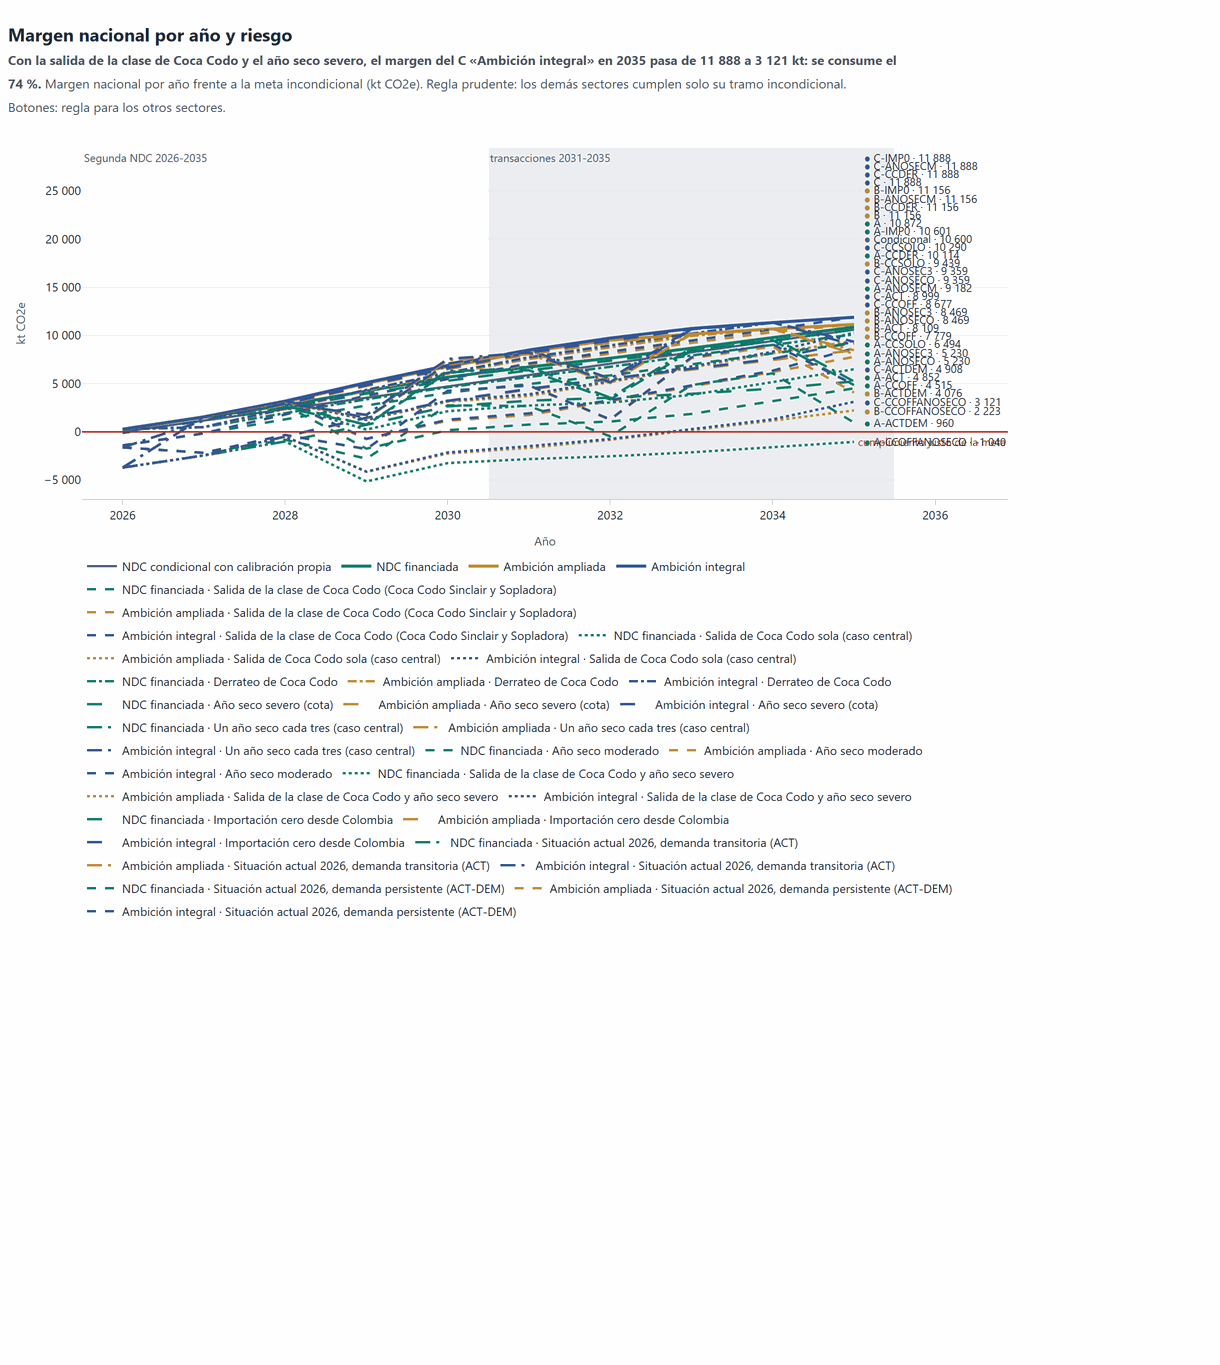

In [30]:
ver('g15_headroom_trayectoria')

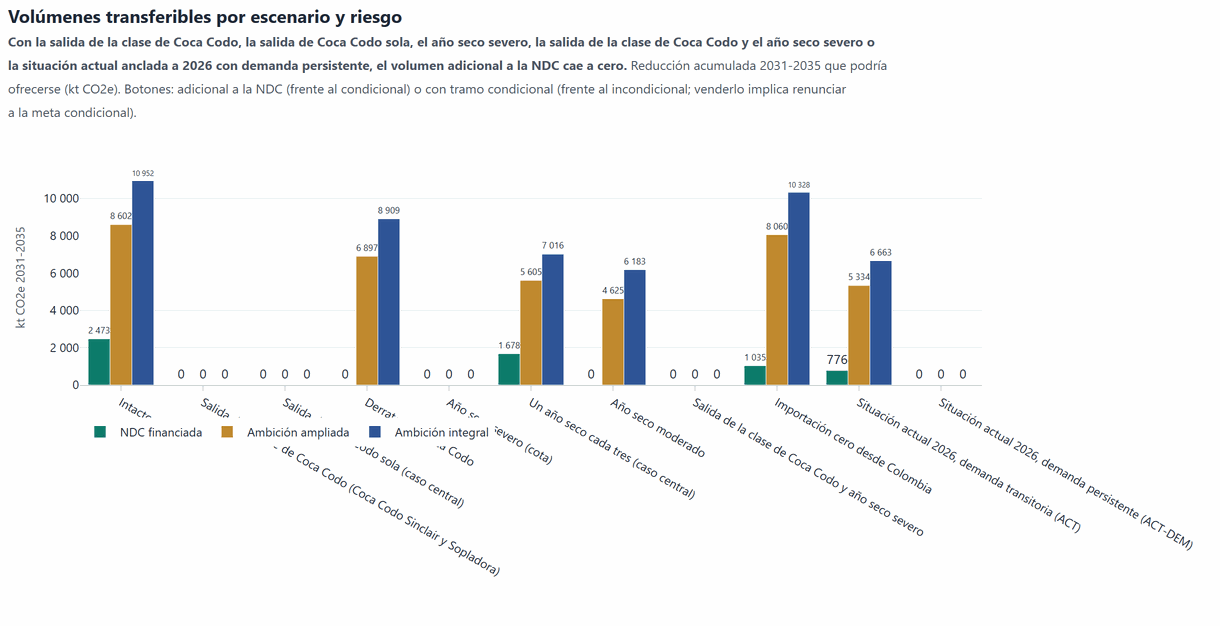

In [31]:
ver('g16_volumenes')

## Fuentes y límites

Fuente de todas las gráficas y fichas: Modelo Climate Lead Group (ECU_NDC, rama art6-escenarios), con los escenarios NDCINC y NDCCON del Modelo CLG, las referencias con calibración propia INCA6 y CONA6 (ajustes de calibración K01-K15) y los escenarios de Artículo 6 definidos en `Energy/B1_Scenario_Config.xlsx`; resultados de la salida de B1 de cada escenario (`Energy/Executables/<ESC>_0/<ESC>_0_Output.csv`). Los años en que un escenario pasa energía por STOELE tienen emisiones subestimadas y los seis escenarios con salida de la clase de Coca Codo no tienen solución con la expansión térmica declarada: ambos casos se leen con la variante diagnóstica de potencia mínima, que no es una cota. Los escenarios son óptimos de mínimo costo con costos de relleno: muestran consecuencias de supuestos documentados, y ninguna cifra de costo por tonelada se sostiene sobre este datafile. El tratamiento del ajuste correspondiente es conceptual y no constituye una metodología oficial bajo el Artículo 6. El mismo contenido está en `docs/_static/tablero_art6.html` (una sola página, sin internet) y en la documentación `docs/_build/html/index.html`. Material de propiedad del PNUD.